# Week 1-Task


## Setup (Colab + Kaggle)

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"mohittrajput","key":"a2200954c7b40cbe0b12910dbdf1ff51"}'}

In [4]:
!pip install kaggle
!mkdir -p /root/.kaggle
!cp kaggle.json /root/.kaggle/
!chmod 600 /root/.kaggle/kaggle.json

In [5]:
!kaggle competitions download -c titanic
!unzip -o titanic.zip

100% 34.1k/34.1k [00:00<00:00, 60.9MB/s]

Archive:  titanic.zip
  inflating: gender_submission.csv   
  inflating: test.csv                
  inflating: train.csv               


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

## What is Machine Learning?
Machine learning is teaching a computer to learn patterns from data so it can make predictions on new data without being programmed with fixed rules.

- **Supervised learning** - data has labels (input and correct output). Example: predicting house price, spam or not spam.
- **Unsupervised learning** - data has no labels, the model finds structure on its own. Example: grouping customers (clustering).
- **Reinforcement learning** - an agent learns by trying actions and getting rewards or penalties. Example: game playing, robots.

## Assignment 1 - Load a dataset and summarize basic stats

In [7]:
df = pd.read_csv('train.csv')
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [8]:
df.shape

(891, 12)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [10]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [11]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


Age, Cabin and Embarked have missing values. Cabin has the most missing values, Embarked has only a couple.

## Assignment 2 - Handle missing data (mean / median imputation)

In [12]:
df_mean = df.copy()
df_mean['Age'] = df_mean['Age'].fillna(df_mean['Age'].mean())

df_median = df.copy()
df_median['Age'] = df_median['Age'].fillna(df_median['Age'].median())

print('original   :', df['Age'].mean(), df['Age'].median())
print('mean fill  :', df_mean['Age'].mean(), df_mean['Age'].std())
print('median fill:', df_median['Age'].mean(), df_median['Age'].std())

original   : 29.69911764705882 28.0
mean fill  : 29.69911764705882 13.002015226002884
median fill: 29.36158249158249 13.019696550973194


I am going with the median for Age because it is not pulled by very old passengers. Embarked is categorical so I fill it with the most frequent value, and Cabin is dropped since most of it is missing.

In [13]:
df2 = df.copy()
df2['Age'] = df2['Age'].fillna(df2['Age'].median())
df2['Embarked'] = df2['Embarked'].fillna(df2['Embarked'].mode()[0])
df2 = df2.drop('Cabin', axis=1)
df2.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


## Assignment 3 - Encode categorical variables

In [14]:
le = LabelEncoder()
df2['Sex_encoded'] = le.fit_transform(df2['Sex'])
print(le.classes_)
df2[['Sex', 'Sex_encoded']].head()

['female' 'male']


,Sex,Sex_encoded
0,male,1
1,female,0
2,female,0
3,female,0
4,male,1


In [15]:
ohe = OneHotEncoder(sparse_output=False)
emb = ohe.fit_transform(df2[['Embarked']])
emb_df = pd.DataFrame(emb, columns=ohe.get_feature_names_out(['Embarked']), index=df2.index)
emb_df.head()

,Embarked_C,Embarked_Q,Embarked_S
0,0.0,0.0,1.0
1,1.0,0.0,0.0
2,0.0,0.0,1.0
3,0.0,0.0,1.0
4,0.0,0.0,1.0


In [16]:
df3 = pd.concat([df2, emb_df], axis=1)
df3.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Sex_encoded,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,1,0.0,0.0,1.0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,0,1.0,0.0,0.0
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,0,0.0,0.0,1.0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,0,0.0,0.0,1.0
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,1,0.0,0.0,1.0


## Mini Project 1 - Titanic Survival Prediction (Data Cleaning)
Dataset: Titanic (Kaggle)

Tasks: clean missing data, encode Sex and Embarked, visualize age distribution, save the cleaned dataset as a new CSV.

In [17]:
titanic = pd.read_csv('train.csv')
age_before = titanic['Age'].copy()
titanic.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


### Clean missing data

In [18]:
titanic['Age'] = titanic['Age'].fillna(titanic['Age'].median())
titanic['Embarked'] = titanic['Embarked'].fillna(titanic['Embarked'].mode()[0])
titanic = titanic.drop(['Cabin', 'Ticket', 'Name', 'PassengerId'], axis=1)
titanic.isnull().sum()

,0
Survived,0
Pclass,0
Sex,0
Age,0
SibSp,0
Parch,0
Fare,0
Embarked,0


### Encode Sex and Embarked

In [19]:
titanic['Sex'] = LabelEncoder().fit_transform(titanic['Sex'])
titanic = pd.get_dummies(titanic, columns=['Embarked'], dtype=int)
titanic.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
0,0,3,1,22.0,1,0,7.2500,0,0,1
1,1,1,0,38.0,1,0,71.2833,1,0,0
2,1,3,0,26.0,0,0,7.9250,0,0,1
3,1,1,0,35.0,1,0,53.1000,0,0,1
4,0,3,1,35.0,0,0,8.0500,0,0,1


Sex: female = 0, male = 1. Embarked is split into three columns (C, Q, S).

### Age distribution

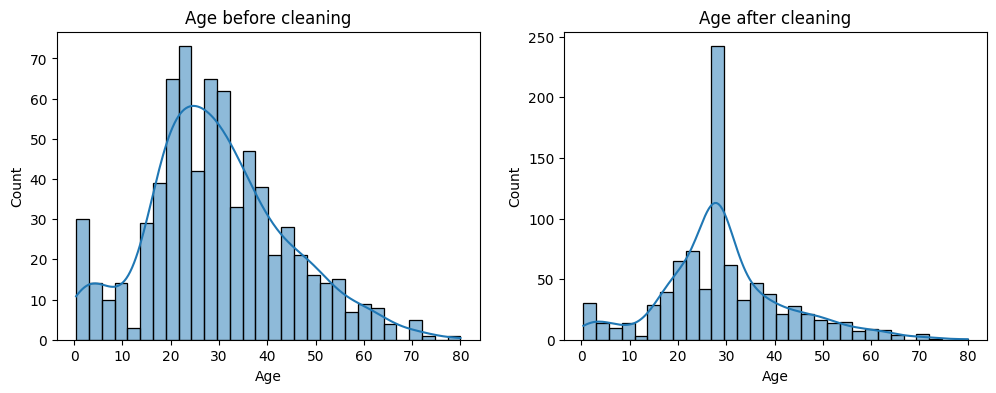

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(age_before.dropna(), bins=30, kde=True, ax=ax[0])
ax[0].set_title('Age before cleaning')
sns.histplot(titanic['Age'], bins=30, kde=True, ax=ax[1])
ax[1].set_title('Age after cleaning')
plt.show()

After filling with the median the bar near the middle ages gets taller, since all the missing values were put at one value.

### Save the cleaned CSV

In [21]:
print(titanic.isnull().sum().sum())
titanic.to_csv('titanic_cleaned.csv', index=False)

0


In [22]:
!cp titanic_cleaned.csv /content/drive/MyDrive/
files.download('titanic_cleaned.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Scaling and train/test split

In [23]:
X = titanic.drop('Survived', axis=1)
y = titanic['Survived']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
cols = ['Age', 'Fare']
X_train = X_train.copy()
X_test = X_test.copy()
X_train[cols] = scaler.fit_transform(X_train[cols])
X_test[cols] = scaler.transform(X_test[cols])

print(X_train.shape, X_test.shape)
X_train.head()

(712, 9) (179, 9)


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
692,3,1,-0.112078,0,0,0.513812,0,0,1
481,2,1,-0.112078,0,0,-0.662563,0,0,1
527,1,1,-0.112078,0,0,3.955399,0,0,1
855,3,0,-0.879807,0,1,-0.467874,0,0,1
801,2,0,0.118241,1,1,-0.115977,0,0,1


## Practice Set - Week 1

**Q1. Load a CSV using pandas and print the first 10 rows**

In [24]:
data = pd.read_csv('train.csv')
data.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


**Q2. Split the dataset into train/test using sklearn**

In [25]:
X = titanic.drop('Survived', axis=1)
y = titanic['Survived']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=1)
print(X_tr.shape, X_te.shape, y_tr.shape, y_te.shape)

(623, 9) (268, 9) (623,) (268,)


**Q3. Train a Linear Regression model and check accuracy**

No housing file was given with the set, so I made a small sample dataset of 100 houses (area in sq ft, price in $1000s). For regression the score used is R2, since normal accuracy is for classification.

In [26]:
np.random.seed(42)
area = np.random.randint(500, 4000, 100)
price = 50 + 0.12 * area + np.random.normal(0, 25, 100)

pd.DataFrame({'area': area, 'price': price.round(2)}).to_csv('houses.csv', index=False)
houses = pd.read_csv('houses.csv')
houses.head()

,area,price
0,3674,487.99
1,1360,205.67
2,1794,228.32
3,1630,227.60
4,1595,229.88


In [27]:
X = houses[['area']]
y = houses['price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print('R2 score:', r2_score(y_test, y_pred))
print('MAE     :', mean_absolute_error(y_test, y_pred))
print('RMSE    :', np.sqrt(mean_squared_error(y_test, y_pred)))
print('slope, intercept:', model.coef_[0], model.intercept_)

R2 score: 0.963070613788566
MAE     : 21.277732771213397
RMSE    : 25.695600138381504
slope, intercept: 0.11976490930731924 47.469687226872736


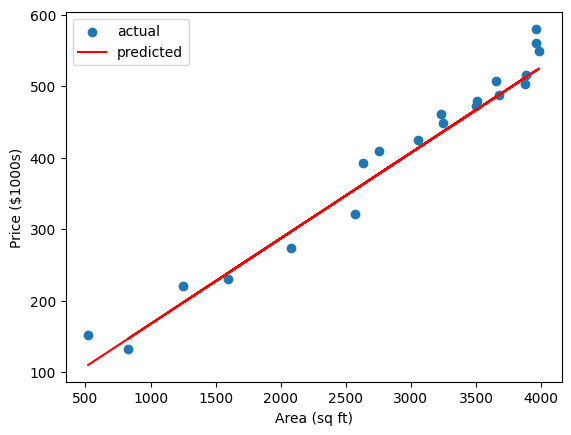

In [28]:
plt.scatter(X_test, y_test, label='actual')
plt.plot(X_test, y_pred, color='red', label='predicted')
plt.xlabel('Area (sq ft)')
plt.ylabel('Price ($1000s)')
plt.legend()
plt.show()

**Q4. Predict house price based on area input**

In [29]:
def predict_price(area):
    return model.predict(pd.DataFrame({'area': [area]}))[0]

for a in [1000, 1800, 2500, 3200]:
    print(a, 'sq ft ->', round(predict_price(a), 2), 'thousand $')

1000 sq ft -> 167.23 thousand $
1800 sq ft -> 263.05 thousand $
2500 sq ft -> 346.88 thousand $
3200 sq ft -> 430.72 thousand $


In [30]:
area = float(input('Enter area in sq ft: '))
print('Predicted price:', round(predict_price(area), 2), 'thousand $')

Enter area in sq ft: 3000
Predicted price: 406.76 thousand $
